# 05. Evaluación final

Desempeño en prueba, análisis de errores, explicabilidad (SHAP), equidad antes y después de la mitigación, confusión del SMS y simulación de asignación.

In [1]:
import sys, json, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.utils import cargar_config, ruta, guardar_json, leer_json
CFG = cargar_config()
FIG = ruta(CFG["rutas"]["figuras"]); MET = ruta(CFG["rutas"]["metricas"])
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
C1, C2, C3, C4 = "#1F3A5F", "#C0504D", "#7F7F7F", "#E1A93B"
def guardar(nombre):
    plt.tight_layout(); plt.savefig(FIG / nombre, bbox_inches="tight"); plt.show()
from src.evaluate import evaluar, cargar_particiones, valores_shap
from src.model import ModeloRiesgo, asignar_grupo_edad
from src.data_processing import FEATURES, ETIQUETAS
EV = evaluar(CFG)
modelo = ModeloRiesgo.cargar(CFG['rutas']['mejor_modelo']); train, test = cargar_particiones(CFG)
p = modelo.predecir_probabilidad(test[FEATURES]); y = test.no_show.values
{k: round(EV[k],4) for k in ['auc_roc','auc_pr','brier','brier_sin_informacion']}

2026-09-26 03:02:06 | INFO | priorizacion | evaluación: AUC 0.7413 | recall global 0.710 | recall mitigado 0.716


{'auc_roc': 0.7413,
 'auc_pr': 0.377,
 'brier': 0.1424,
 'brier_sin_informacion': 0.1612}

In [2]:
pd.DataFrame({'umbral 0.5': EV['umbral_05'], f"umbral global {EV['umbral_global']['umbral']:.3f}": {k: EV['umbral_global'][k] for k in EV['umbral_05']}, 'umbral por grupo de edad': EV['umbral_mitigado']}).round(3)

,umbral 0.5,umbral global 0.242,umbral por grupo de edad
precision,0.555,0.334,0.320
recall,0.017,0.710,0.716
f1,0.033,0.454,0.442
exactitud,0.799,0.655,0.636
porcentaje_senalado,0.006,0.430,0.451


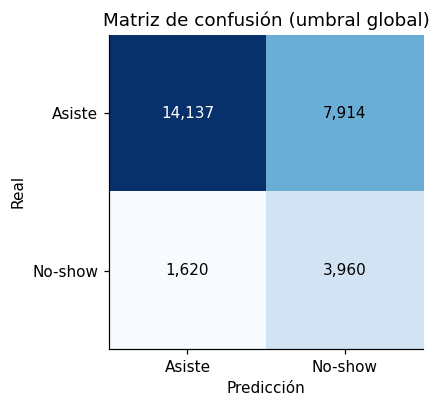

In [3]:
cm = np.array(EV['umbral_global']['matriz_confusion'])
fig, ax = plt.subplots(figsize=(4.4,3.8)); ax.imshow(cm, cmap='Blues'); ax.grid(False)
for i in range(2):
    for j in range(2): ax.text(j,i,f'{cm[i,j]:,}',ha='center',va='center',color='white' if cm[i,j]>8000 else 'black')
ax.set_xticks([0,1],['Asiste','No-show']); ax.set_yticks([0,1],['Asiste','No-show']); ax.set_xlabel('Predicción'); ax.set_ylabel('Real'); ax.set_title('Matriz de confusión (umbral global)')
guardar('16_matriz_confusion.png')

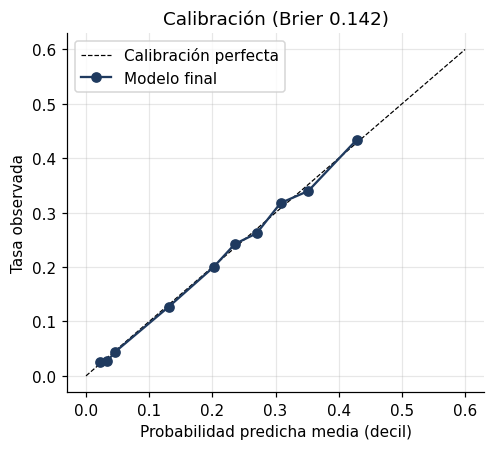

In [4]:
c = EV['calibracion']; fig, ax = plt.subplots(figsize=(4.6,4.2)); ax.plot([0,.6],[0,.6],'k--',lw=.8, label='Calibración perfecta')
ax.plot(c['prob_media'], c['tasa_observada'], 'o-', color=C1, label='Modelo final'); ax.set_xlabel('Probabilidad predicha media (decil)'); ax.set_ylabel('Tasa observada'); ax.legend(); ax.set_title(f"Calibración (Brier {EV['brier']:.3f})")
guardar('17_calibracion.png')

## Explicabilidad: SHAP

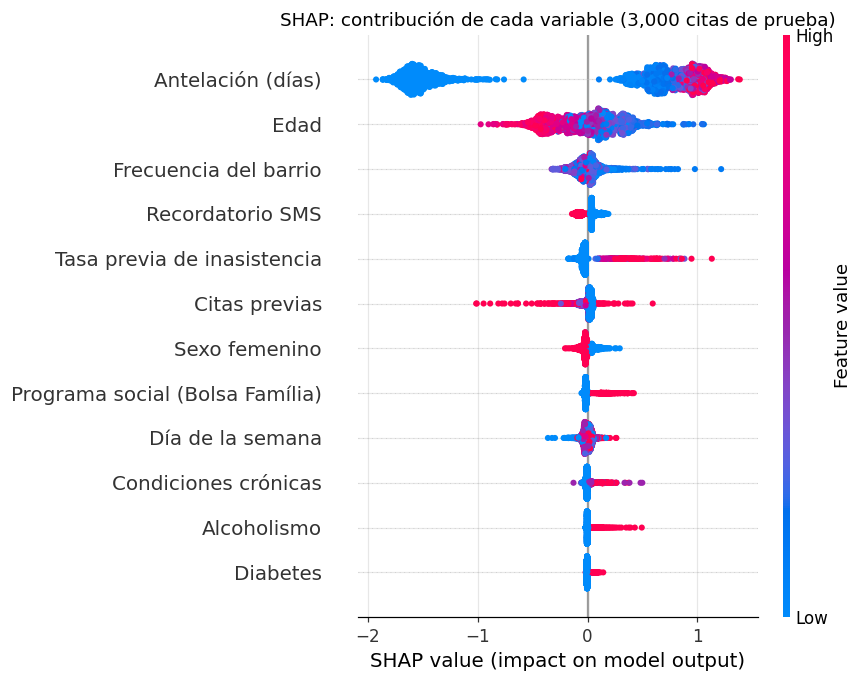

In [5]:
import shap
exp, muestra, sv = valores_shap(modelo, test[FEATURES])
shap.summary_plot(sv, muestra.rename(columns=ETIQUETAS), show=False, max_display=12)
plt.title('SHAP: contribución de cada variable (3,000 citas de prueba)'); guardar('18_shap_resumen.png')

In [6]:
imp = pd.DataFrame({'SHAP medio |valor|': EV['shap_media_abs'], 'caída de AUC (permutación)': {k: v['media'] for k, v in EV['importancia_permutacion'].items()}}).sort_values('SHAP medio |valor|', ascending=False)
imp.rename(index=ETIQUETAS).round(4)

,SHAP medio |valor|,caída de AUC (permutación)
Antelación (días),1.0496,0.2132
Edad,0.2439,0.0383
Frecuencia del barrio,0.0809,0.0076
Recordatorio SMS,0.0654,0.0058
Tasa previa de inasistencia,0.0626,0.0058
Citas previas,0.0404,0.0036
Sexo femenino,0.0365,0.0014
Programa social (Bolsa Família),0.0309,0.0013
Día de la semana,0.0290,0.0020
Condiciones crónicas,0.0222,0.0018


## Equidad por grupo de edad y mitigación implementada

In [7]:
eq = pd.DataFrame(EV['equidad']); eq[['grupo','n','tasa_base','auc','recall_global','senalado_global','umbral_mitigado','recall_mitigado','senalado_mitigado','precision_mitigado']].round(3)

,grupo,n,tasa_base,auc,recall_global,senalado_global,umbral_mitigado,recall_mitigado,senalado_mitigado,precision_mitigado
0,0 a 18,7356,0.218,0.745,0.823,0.530,0.283,0.703,0.417,0.368
1,19 a 35,6029,0.237,0.736,0.909,0.624,0.306,0.729,0.464,0.372
2,36 a 55,7428,0.198,0.730,0.685,0.429,0.239,0.704,0.445,0.313
3,56 a 64,3224,0.163,0.714,0.317,0.149,0.189,0.723,0.467,0.252
4,65 o más,3594,0.154,0.707,0.306,0.152,0.182,0.740,0.499,0.228
5,Mujeres,18371,0.203,0.737,0.709,0.433,NaN,NaN,NaN,NaN
6,Hombres,9260,0.200,0.750,0.711,0.422,NaN,NaN,NaN,NaN


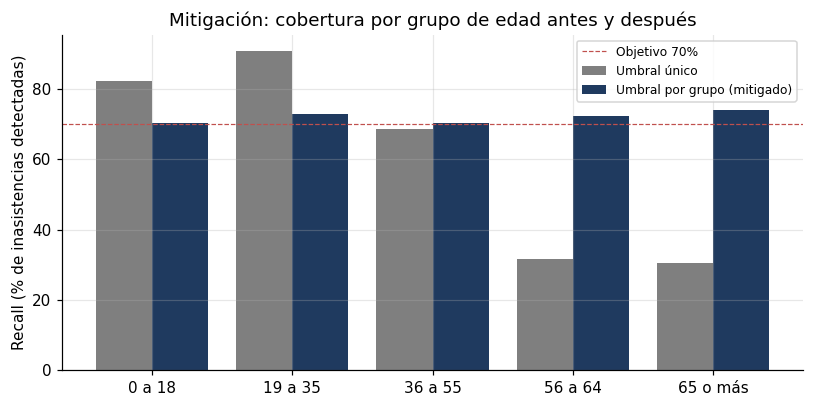

In [8]:
e5 = eq.head(5); x = np.arange(5); fig, ax = plt.subplots(figsize=(7.5,3.8))
ax.bar(x-.2, 100*e5.recall_global, .4, color=C3, label='Umbral único'); ax.bar(x+.2, 100*e5.recall_mitigado, .4, color=C1, label='Umbral por grupo (mitigado)')
ax.axhline(70, color=C2, ls='--', lw=.8, label='Objetivo 70%'); ax.set_xticks(x, e5.grupo); ax.set_ylabel('Recall (% de inasistencias detectadas)'); ax.legend(fontsize=8)
ax.set_title('Mitigación: cobertura por grupo de edad antes y después'); guardar('19_equidad_mitigacion.png')

## Análisis de errores: dónde funciona bien y dónde no

In [9]:
d = test.assign(p=p, pred=(p >= modelo.umbral_global).astype(int))
d['tramo_antelacion'] = pd.cut(d.lead_time_days, [-1,0,7,30,400], labels=['0','1-7','8-30','31+'])
from sklearn.metrics import roc_auc_score
err = d.groupby('tramo_antelacion', observed=True).apply(lambda g: pd.Series({'citas': len(g), 'tasa_no_show': g.no_show.mean(), 'AUC': roc_auc_score(g.no_show, g.p) if g.no_show.nunique()>1 else np.nan,
      'falsos_positivos_%': ((g.pred==1)&(g.no_show==0)).mean(), 'falsos_negativos_%': ((g.pred==0)&(g.no_show==1)).mean()}))
err.round(3)

,citas,tasa_no_show,AUC,falsos_positivos_%,falsos_negativos_%
tramo_antelacion,,,,,
0,9580.0,0.044,0.676,0.008,0.039
1-7,7986.0,0.240,0.587,0.326,0.107
8-30,7376.0,0.314,0.615,0.534,0.036
31+,2689.0,0.344,0.602,0.484,0.047


In [10]:
fn = d[(d.pred==0)&(d.no_show==1)]; fp = d[(d.pred==1)&(d.no_show==0)]
pd.DataFrame({'falsos negativos': fn[['Age','lead_time_days','prior_appts','SMS_received']].median(), 'falsos positivos': fp[['Age','lead_time_days','prior_appts','SMS_received']].median(), 'todos': d[['Age','lead_time_days','prior_appts','SMS_received']].median()})

,falsos negativos,falsos positivos,todos
Age,54.0,28.0,37.0
lead_time_days,3.0,14.0,4.0
prior_appts,0.0,0.0,0.0
SMS_received,0.0,0.0,0.0


## Confusión del SMS

In [11]:
EV['confusion_sms']

{'tasa_sin_sms': 0.16703533926762965,
 'tasa_con_sms': 0.27574544839637,
 'or_ajustado': 0.772853694994499,
 'or_ic95': [0.7454178702841298, 0.8012993217334285]}

## Simulación de asignación geográfica (cinco políticas)

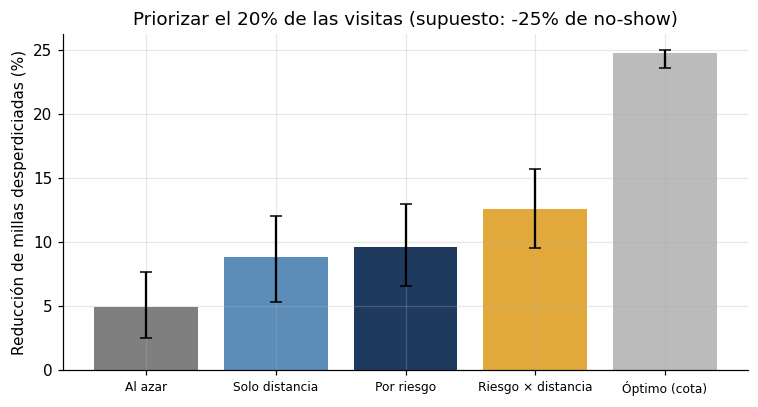

,política,reducción media %,IC 95%
0,Al azar,4.97,2.5 a 7.7
1,Solo distancia,8.86,5.3 a 12.1
2,Por riesgo,9.63,6.6 a 13.0
3,Riesgo × distancia,12.56,9.5 a 15.7
4,Óptimo (cota),24.75,23.6 a 25.0


In [12]:
from src.simulation import POLITICAS
sim = EV['simulacion']['principal']
tab = pd.DataFrame([{'política': POLITICAS[k], 'reducción media %': v['media'], 'IC 95%': f"{v['ic95'][0]:.1f} a {v['ic95'][1]:.1f}"} for k, v in sim.items()])
fig, ax = plt.subplots(figsize=(7,3.8)); m = [v['media'] for v in sim.values()]
lo = [v['media']-v['ic95'][0] for v in sim.values()]; hi = [v['ic95'][1]-v['media'] for v in sim.values()]
ax.bar(range(5), m, yerr=[lo,hi], capsize=4, color=[C3,'#5B8DB8',C1,C4,'#BBBBBB']); ax.set_xticks(range(5), list(POLITICAS.values()), fontsize=8)
ax.set_ylabel('Reducción de millas desperdiciadas (%)'); ax.set_title('Priorizar el 20% de las visitas (supuesto: -25% de no-show)')
guardar('20_simulacion.png'); tab.round(2)

In [13]:
pd.DataFrame({r: {POLITICAS[k]: v['media'] for k, v in d_.items()} for r, d_ in {'0.15': EV['simulacion']['sensibilidad_efecto']['0.15'], '0.25': sim, '0.35': EV['simulacion']['sensibilidad_efecto']['0.35'], '0.50': EV['simulacion']['sensibilidad_efecto']['0.5']}.items()}).round(1)

,0.15,0.25,0.35,0.50
Al azar,3.0,5.0,7.0,9.9
Solo distancia,5.3,8.9,12.4,17.8
Por riesgo,5.7,9.6,13.4,19.2
Riesgo × distancia,7.5,12.6,17.5,25.0
Óptimo (cota),14.9,24.8,34.7,49.5


## Conclusiones de la evaluación
Ver `docs/arquitectura.md` y `docs/consideraciones_eticas.md` para la interpretación completa. Resumen: AUC 0.741 (0.039 sobre la referencia de solo antelación), probabilidades bien calibradas, brecha de cobertura en adultos mayores corregida con umbrales por grupo, y un aporte del modelo en la simulación de 3.7 puntos sobre la mejor política sin modelo.